# 03 - Corpus & BM25 Index

Roadmap **Bước 1.4**:
- Chỉ giữ điều luật của 48 bang có trong `questions`
- Chunking điều luật dài, mỗi đoạn giữ `citation`, `path`, `state`, `statute_idx`
- Một index BM25 (`bm25s`) cho mỗi bang để M3 chỉ tìm trong luật của đúng bang được hỏi
- Kiểm tra index chỉ chứa văn bản luật, không chứa câu hỏi hay đáp án

Đầu ra: `data/index/<state-slug>/` (index + `corpus.jsonl` các chunk), `data/index/manifest.json`. Chạy mất vài chục phút, không commit.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))

In [2]:
import gc
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from transformers import AutoTokenizer

from legal_qa.data import HousingQA
from legal_qa.data.corpus import CHUNK_OVERLAP, CHUNK_WORDS, chunk_words, clean_text
from legal_qa.data.housingqa import load_statutes, state_key
from legal_qa.data.indexing import build_corpus_indexes, load_state_index, search
from legal_qa.data.preprocessing import MODEL_NAME
from legal_qa.paths import FIGURES_DIR, INDEX_DIR, TABLES_DIR

[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


In [3]:
splits = HousingQA().splits()
all_records = [r for rows in splits.values() for r in rows]
STATES = sorted({r["state"] for r in all_records})
print(len(STATES), "bang")

48 bang


## 1. Kho điều luật

In [4]:
t0 = time.time()
statutes = load_statutes(STATES)
# str.count thay cho str.split (tốn >20 GB RAM).
statutes["n_words"] = statutes["text"].str.count(r"\S+")
print(f"{len(statutes):,} điều luật của {statutes['state'].nunique()} bang ({time.time() - t0:.0f}s)")
statutes["n_words"].describe(percentiles=[0.5, 0.9, 0.99]).round(1)

1,787,372 điều luật của 48 bang (113s)


count    1787372.0
mean         251.0
std          590.8
min            1.0
50%          128.0
90%          542.0
99%         1908.0
max       358143.0
Name: n_words, dtype: float64

**Nhận xét:** 1.787.372 điều luật của 48 bang, trung vị 128 từ nhưng đuôi rất dài (p99 khoảng 1.900 từ, dài nhất 358.143 từ), nên phải chunking.

In [5]:
gold = {i for r in all_records for i in r["gold_statute_idx"]}
gold_rows = statutes[statutes["idx"].isin(gold)]
state_of = dict(zip(gold_rows["idx"], gold_rows["state"]))
mismatch = sum(state_of.get(i) != state_key(r["state"]) for r in all_records for i in r["gold_statute_idx"])
print(f"Gold statute có trong kho: {len(gold_rows)}/{len(gold)} | gold statute khác bang của câu hỏi: {mismatch}")

Gold statute có trong kho: 986/986 | gold statute khác bang của câu hỏi: 0


**Nhận xét:** toàn bộ 986 gold statute (sau khi bỏ 9 dòng mâu thuẫn ở notebook 02) đều có trong kho và đúng bang của câu hỏi, nên đo Recall@k bằng `statute_idx` được.

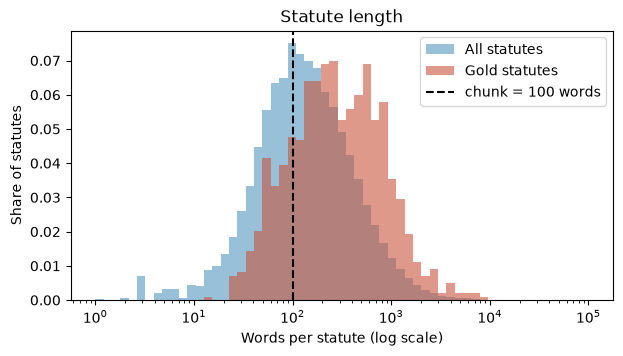

Gold statute: {'count': 986.0, 'mean': 497.6, 'std': 740.2, 'min': 15.0, '50%': 266.0, '90%': 1049.0, 'max': 9229.0}


In [6]:
fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.logspace(0, 5, 60)
ax.hist(statutes["n_words"].clip(lower=1), bins=bins, color="#98C1D9", label="All statutes",
        weights=np.full(len(statutes), 1 / len(statutes)))
ax.hist(gold_rows["n_words"].clip(lower=1), bins=bins, color="#C8553D", alpha=0.6, label="Gold statutes",
        weights=np.full(len(gold_rows), 1 / len(gold_rows)))
ax.axvline(CHUNK_WORDS, color="black", ls="--", label=f"chunk = {CHUNK_WORDS} words")
ax.set_xscale("log")
ax.set_xlabel("Words per statute (log scale)")
ax.set_ylabel("Share of statutes")
ax.set_title("Statute length")
ax.legend()
fig.savefig(FIGURES_DIR / "statute_length.png", dpi=150, bbox_inches="tight")
plt.show()
print("Gold statute:", gold_rows["n_words"].describe(percentiles=[0.5, 0.9]).round(1).to_dict())

**Nhận xét:** gold statute dài hơn mặt bằng chung (trung vị 266 từ so với 128 từ), phần lớn bị cắt thành nhiều chunk. Vì vậy mỗi chunk giữ `statute_idx` gốc và Recall@k tính theo điều luật.

## 2. Chọn kích thước chunk

M3 đưa câu hỏi cùng top-k đoạn vào Flan-T5 với `max_source_len = 512`; câu hỏi có trung vị 32 token (dài nhất 121). Kích thước chunk được chọn sao cho với câu hỏi thông thường, k = 3 đoạn vừa phần còn lại.

In [7]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
sample = statutes.sample(3000, random_state=42)["text"].map(clean_text)
tok_per_word = sum(len(tokenizer(t).input_ids) for t in sample) / sum(len(t.split()) for t in sample)
print(f"Token/từ (Flan-T5) ≈ {tok_per_word:.2f}")
print(f"Chunk {CHUNK_WORDS} từ (overlap {CHUNK_OVERLAP}) ≈ {CHUNK_WORDS * tok_per_word:.0f} token; "
      f"3 chunk ≈ {3 * CHUNK_WORDS * tok_per_word:.0f} token")
print(f"Điều luật ≤ {CHUNK_WORDS} từ (giữ nguyên 1 chunk): {(statutes['n_words'] <= CHUNK_WORDS).mean():.1%}")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (656 > 512). Running this sequence through the model will result in indexing errors


Token/từ (Flan-T5) ≈ 1.45
Chunk 100 từ (overlap 20) ≈ 145 token; 3 chunk ≈ 436 token
Điều luật ≤ 100 từ (giữ nguyên 1 chunk): 41.0%


**Nhận xét:** văn bản điều luật ra khoảng 1,45 token/từ (cao hơn câu hỏi vì nhiều số hiệu và ký hiệu §), nên chốt **chunk 100 từ, overlap 20**: 3 chunk khoảng 436 token, cộng câu hỏi (trung vị 32 token) vẫn vừa 512. Với k = 5, M3 phải cắt bớt từng đoạn. 41% điều luật đủ ngắn để giữ nguyên 1 chunk.

In [8]:
example = statutes.loc[statutes["n_words"].between(260, 300)].iloc[0]
for i, c in enumerate(chunk_words(clean_text(example["text"]))):
    print(f"[{example['citation']} | chunk {i}] {len(c.split())} từ: {c[:150]}...")

[MO Rev Stat § 1.307 (2021) | chunk 0] 100 từ: Effective - 28 Aug 2003 1.307. Applicability of religious freedom restoration act — limitations — relevant circumstances defined. — 1. Section 1.302 a...
[MO Rev Stat § 1.307 (2021) | chunk 1] 100 từ: in these sections shall be construed to establish or eliminate a defense to a civil action or criminal prosecution based on a federal, state, or local...
[MO Rev Stat § 1.307 (2021) | chunk 2] 100 từ: a life-threatening condition. 4. "Relevant circumstances" may include legitimate penological interests needed to protect the safety and security of in...
[MO Rev Stat § 1.307 (2021) | chunk 3] 38 từ: and the First Amendment's right to expressive association, and the city failed to show that ordinance furthered a compelling government interest or wa...


## 3. Build index BM25 theo bang

In [9]:
# Kiểm tra không câu hỏi nào xuất hiện nguyên văn trong index.
questions_by_state = {}
for r in all_records:
    questions_by_state.setdefault(r["state"], []).append(r["question"])

t0 = time.time()
index_stats = build_corpus_indexes(statutes, STATES, INDEX_DIR, leak_check_questions=questions_by_state)
print(f"Tổng thời gian: {(time.time() - t0) / 60:.1f} phút")

Alabama                statutes=  43768 chunks= 134147 27.1s


Alaska                 statutes=  17706 chunks=  50608 10.5s


Arizona                statutes=  15259 chunks=  63072 11.2s


Arkansas               statutes=  33857 chunks= 106483 14.3s


California             statutes= 155974 chunks= 412247 39.3s


Colorado               statutes=  30056 chunks= 198907 21.2s


... (39 outputs left out)

West Virginia          statutes=  25580 chunks= 100000 18.3s


Wisconsin              statutes=  17739 chunks= 123416 22.2s


Wyoming                statutes=  15777 chunks=  51486 8.8s


Tổng thời gian: 10.5 phút


In [10]:
index_stats.to_csv(TABLES_DIR / "corpus_index_stats.csv", index=False)
assert index_stats["question_leaks"].sum() == 0
print(f"Tổng: {index_stats['n_statutes'].sum():,} điều luật -> {index_stats['n_chunks'].sum():,} chunk")
index_stats.sort_values("n_chunks", ascending=False)

Tổng: 1,787,372 điều luật -> 6,147,308 chunk


,state,slug,n_statutes,n_chunks,chunks_per_statute,question_leaks,build_seconds
4,California,california,155974,412247,2.64,0,39.3
40,Texas,texas,117589,262044,2.23,0,21.6
30,New York,new-york,37049,229745,6.20,0,17.7
5,Colorado,colorado,30056,198907,6.62,0,21.2
17,Louisiana,louisiana,49988,180061,3.60,0,13.6
44,Washington,washington,50091,175246,3.50,0,29.9
28,New Jersey,new-jersey,54513,167719,3.08,0,12.5
21,Michigan,michigan,42481,167454,3.94,0,16.0
10,Georgia,georgia,28679,166851,5.82,0,16.7
32,Ohio,ohio,32662,155321,4.76,0,12.6


**Nhận xét:** tổng cộng 6.147.308 chunk (khoảng 3,4 chunk mỗi điều luật), index 7,6 GB, build mất khoảng 10–13 phút; RAM đỉnh khoảng 7,3 GB (chạy được trên Colab bản miễn phí). Không có câu hỏi nào (cả 3 tập) xuất hiện nguyên văn trong index: index chỉ chứa văn bản luật đọc từ `statutes.tsv`.

In [11]:
del statutes, gold_rows
gc.collect();

## 4. Sanity check

Kiểm tra nhanh index load và truy xuất được. Đánh giá chính thức (Recall@k trên val/test, chọn k) làm ở notebook M3.

In [12]:
r = splits["val"][0]
retriever = load_state_index(r["state"])
print(r["input_text"], "->", r["answer"], "| gold:", [s["citation"] for s in r["statutes"]])
for hit in search(retriever, r["question"], k=3):
    print(f"  {hit['score']:.2f} {hit['citation']} {'(gold)' if hit['statute_idx'] in r['gold_statute_idx'] else ''}")

state: Alabama question: Is it specified whether a landlord waives their right to evict for nonpayment of rent by accepting partial payment of rent? -> yes | gold: ['ALA. CODE § 35-9A-424']
  16.56 AL Code § 35-9A-461 (2021) 
  14.52 AL Code § 35-9A-461 (2021) 
  14.17 AL Code § 35-9A-461 (2021) 


In [13]:
# Recall@k theo top-k chunk và theo top-k điều luật khác nhau (như bài báo).
KS = (1, 3, 5, 10)
chunk_hits, statute_hits = {k: [] for k in KS}, {k: [] for k in KS}
for state in sorted({r["state"] for r in splits["val"]}):
    retriever = load_state_index(state)
    for r in (x for x in splits["val"] if x["state"] == state):
        ids = [h["statute_idx"] for h in search(retriever, r["question"], k=50)]
        unique_ids = list(dict.fromkeys(ids))
        gold = set(r["gold_statute_idx"])
        for k in KS:
            chunk_hits[k].append(bool(set(ids[:k]) & gold))
            statute_hits[k].append(bool(set(unique_ids[:k]) & gold))
pd.DataFrame({
    "top-k chunks": {f"Recall@{k}": np.mean(v) for k, v in chunk_hits.items()},
    "top-k unique statutes": {f"Recall@{k}": np.mean(v) for k, v in statute_hits.items()},
}).round(3)

,top-k chunks,top-k unique statutes
Recall@1,0.106,0.106
Recall@3,0.191,0.209
Recall@5,0.252,0.280
Recall@10,0.323,0.386


**Nhận xét:** Recall@10 trên val đạt **38,6%** khi tính theo điều luật khác nhau, gần mức 40,8% của BM25 trong bài báo HousingQA (bài báo tính trên toàn bộ câu hỏi), nên cài đặt hợp lý. Tính theo chunk thì thấp hơn (32,3%), vì top-k hay có nhiều chunk của cùng một điều luật (như ví dụ ở trên): M3 có thể cân nhắc gộp các chunk cùng `statute_idx`.